# Acciones individuales

Ejecuta todas las celdas. Este notebook descarga/carga, limpia y actualiza los CSV
que alimentan `04_conclusiones.ipynb`. Configuración común en `config.toml`.

**El ISIN es la identidad del activo.** Solo se estudian ISIN del catálogo cargado de
Trade Republic. Si el catálogo o la cobertura de precios son parciales se indica expresamente.
El PDF público no incluye los fondos tradicionales; consulta el README para aportar su catálogo.

Precio: último cierre o valor liquidativo, no cotización intradía. Se conserva el cierre
y su precio ajustado por dividendos/distribuciones y splits. Retorno logarítmico:
`ln(precio_ajustado_hoy / precio_ajustado_anterior)`.

Se elimina el duplicado de fecha conservando la última fila y se auditan los conflictos.
Se rellenan huecos de lunes a viernes con el dato anterior, incluidos festivos, sin añadir fines de
semana ni extender un activo más allá de su último dato. No se rellena hacia atrás.
Un exceso de huecos o un precio antiguo excluyen el activo del ranking.


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path(os.environ["TR_PIPELINE_ROOT"]).resolve() if os.getenv("TR_PIPELINE_ROOT") else Path.cwd()
if not (ROOT / "config.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from tr_pipeline.pipeline import run_asset_type, conclusions
from tr_pipeline.notebook import show_coverage, show_eda, show_rankings
from IPython.display import display, Markdown
import pandas as pd

REFRESH = False  # True fuerza una descarga nueva de Yahoo y divisas.
OFFLINE = os.getenv("TR_PIPELINE_OFFLINE", "0") == "1"


## 1. Pipeline y cobertura

Una correspondencia dudosa entre ISIN y ticker queda pendiente para revisión.

In [2]:
RESULT = run_asset_type(ROOT, "stock", refresh=REFRESH, offline=OFFLINE)
show_coverage(RESULT)

[stock 1/250] US0378331005 Apple
[stock 2/250] US67066G1040 NVIDIA
[stock 3/250] DE0008404005 Allianz
[stock 4/250] US02079K3059 Alphabet (A)
[stock 5/250] US5949181045 Microsoft
[stock 6/250] US0231351067 Amazon.com
[stock 7/250] US84615Q1031 SpaceX
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[stock 8/250] US0846707026 Berkshire Hathaway (B)
[stock 9/250] DE0007030009 Rheinmetall
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[stock 10/250] US7561091049 Realty Income
[stock 11/250] NL0010273215 ASML
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[stock 12/250] DE0008430026 Münchener Rück
[stock 13/250] US1912161007 Coca-Cola
[stock 14/250] US88160R1014 Tesla
[stock 15/250] DE000ENER6Y0 Siemens Energy
  Pendiente: Sin correspondencia Yahoo verificable para este ISIN y tipo. Revisar mappings.csv.
[stock 16/250] US5801351017 McDonald's
[sto

### Acciones
Referencia: **2026-11-04**. Catálogo cargado: **250** ISIN. Con precios: **188**. Elegibles: **184**. Pendientes/error: **62**.

Selección: **250** de **11323** publicados. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). El ranking por rentabilidad se calcula después sobre esta selección.

**RESULTADOS PARCIALES: no son el top de todo Trade Republic.**

Selección: 250 ISIN de 11323 publicados; catálogo cargado: 250. Criterio: Orden predeterminado del explorador público TR (proxy de relevancia; fórmula no publicada). La disponibilidad en una cuenta concreta puede variar.

## 2. Limpieza, EDA y medias

Medias de los últimos 3, 6 y 12 meses naturales. Comparación en EUR, usando la misma serie ajustada. Los huecos imputados se conservan con una marca para auditar su efecto.

### Limpieza: duplicados, huecos y splits

,isin,raw_rows,duplicate_dates,conflicting_duplicates,invalid_dates,weekend_rows_removed,missing_business_days,imputed_fraction,observed_rows,clean_rows,split_events,first_date,last_date,warnings
0,US0378331005,1720,0,0,0,0,65,0.036415,1720,1785,1,2020-01-02,2026-11-04,NaN
1,US67066G1040,1720,0,0,0,0,65,0.036415,1720,1785,2,2020-01-02,2026-11-04,NaN
2,DE0008404005,1744,0,0,0,0,41,0.022969,1744,1785,0,2020-01-02,2026-11-04,NaN
3,US02079K3059,1720,0,0,0,0,65,0.036415,1720,1785,1,2020-01-02,2026-11-04,NaN
4,US5949181045,1720,0,0,0,0,65,0.036415,1720,1785,0,2020-01-02,2026-11-04,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,IT0004176001,1742,0,0,0,0,43,0.024090,1742,1785,0,2020-01-02,2026-11-04,NaN
184,BE0003604155,1754,0,0,0,0,31,0.017367,1754,1785,0,2020-01-02,2026-11-04,NaN
185,DE000TLX1005,1744,0,0,0,0,41,0.022969,1744,1785,0,2020-01-02,2026-11-04,NaN
186,FR0000131104,1754,0,0,0,0,31,0.017367,1754,1785,0,2020-01-02,2026-11-04,NaN


### ISIN pendientes de fuente o correspondencia

,isin,name,reason
0,US84615Q1031,SpaceX,Sin correspondencia Yahoo verificable para est...
1,DE0007030009,Rheinmetall,Sin correspondencia Yahoo verificable para est...
2,NL0010273215,ASML,Sin correspondencia Yahoo verificable para est...
3,DE000ENER6Y0,Siemens Energy,Sin correspondencia Yahoo verificable para est...
4,US8740391003,TSMC (ADR),Sin correspondencia Yahoo verificable para est...
...,...,...,...
57,SG1L01001701,DBS Group Holdings,Sin correspondencia Yahoo verificable para est...
58,US8334451098,Snowflake (A),Sin correspondencia Yahoo verificable para est...
59,NL0011585146,Ferrari,Sin correspondencia Yahoo verificable para est...
60,US03831W1080,AppLovin,Sin correspondencia Yahoo verificable para est...


### Estadística descriptiva

,count,mean,std,min,25%,50%,75%,max
return_3m_pct,188.0,-0.443926,18.183365,-53.859287,-11.127839,1.445311,11.995369,59.745973
return_6m_pct,188.0,6.396454,26.594677,-67.275015,-7.187666,9.102466,22.811371,95.826165
return_12m_pct,188.0,14.100547,44.254013,-71.437335,-11.647551,13.744974,35.091006,272.407334
daily_log_return_mean,188.0,0.000476,0.000492,-0.000796,0.000202,0.000466,0.000710,0.002664
annualized_volatility_pct,188.0,42.107263,22.064575,18.391646,28.925335,34.371072,48.397730,140.290098
max_drawdown_pct,188.0,-56.020715,17.909342,-98.961532,-67.991000,-54.255803,-41.198524,-22.982886


### Medias de 3, 6 y 12 meses frente al último precio ajustado en EUR
`vs_mean_*_pct`: cuánto está el precio por encima (+) o por debajo (-) de esa media.

,isin,name,adjusted_price_eur,mean_3m,vs_mean_3m_pct,mean_6m,vs_mean_6m_pct,mean_12m,vs_mean_12m_pct,last_date
0,US0378331005,Apple,310.207609,288.087394,7.678300,276.961514,12.003868,252.233733,22.984188,2026-11-04
1,US67066G1040,NVIDIA,177.625386,193.358818,-8.136909,186.881207,-4.952783,172.917058,2.722882,2026-11-04
2,DE0008404005,Allianz,458.399994,435.851515,5.173431,418.098394,9.639262,387.803518,18.204187,2026-11-04
3,US02079K3059,Alphabet (A),256.439815,296.082723,-13.389132,306.524453,-16.339524,288.024606,-10.966004,2026-11-04
4,US5949181045,Microsoft,493.300279,446.460883,10.491265,398.243685,23.868952,385.774847,27.872588,2026-11-04
...,...,...,...,...,...,...,...,...,...,...
183,IT0004176001,Prysmian,104.400002,120.089091,-13.064542,130.635076,-20.082718,113.748241,-8.218360,2026-11-04
184,BE0003604155,Lotus Bakeries,14000.000000,12586.363636,11.231492,11817.817250,18.465193,10463.807597,33.794509,2026-11-04
185,DE000TLX1005,Talanx,133.300003,121.989394,9.271797,114.987393,15.925754,110.520319,20.611309,2026-11-04
186,FR0000131104,BNP Paribas,91.699997,96.818423,-5.286624,95.805039,-4.284787,87.438402,4.873825,2026-11-04


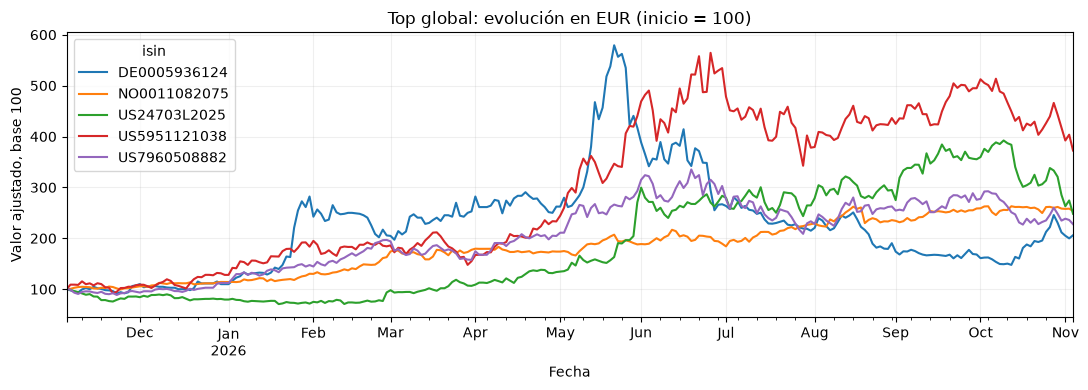

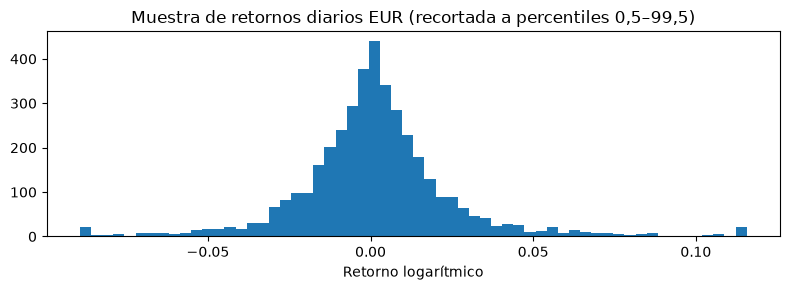

In [3]:
show_eda(ROOT, "stock", RESULT)

## 3. PER y EPS: posibles candidatos para estudiar

PER histórico anual = **precio medio del año fiscal / EPS diluido anual positivo**.
Se compara la mediana de al menos tres años con el PER TTM actual publicado por Yahoo.
Es una comparación retrospectiva aproximada, no una serie de PER TTM históricos ni un backtest.
Los informes pueden estar reformulados. No se utiliza PER forward como si fuera realizado.

Solo se compara con EPS en la misma divisa y base de acciones. Si hay splits y esa base
no se puede comprobar, se necesitan los EPS ajustados de los informes del emisor.
PER un 20% inferior a su mediana: candidato a revisar por value.
PER un 20% superior y crecimiento positivo de beneficios: candidato a revisar por growth.
La deuda, márgenes, ROE, crecimiento de ingresos y EPS esperado se muestran cuando están publicados.
Son reglas exploratorias; no valoran por sí solas el negocio ni predicen su rendimiento.


In [4]:
metrics = RESULT["metrics"]
if not metrics.empty:
    display(metrics[["isin", "name", "pe_current", "pe_forward", "eps_ttm", "eps_forward",
                     "pe_historical_median", "pe_discount_pct", "earnings_growth", "revenue_growth",
                     "roe", "debt_to_equity", "profit_margin", "valuation_signal", "valuation_reason"]])
    display(pd.read_csv(ROOT / "data/processed/stock/pe_annual.csv"))
else:
    display(Markdown("No hay comparaciones de PER disponibles."))

,isin,name,pe_current,pe_forward,eps_ttm,eps_forward,pe_historical_median,pe_discount_pct,earnings_growth,revenue_growth,roe,debt_to_equity,profit_margin,valuation_signal,valuation_reason
0,US0378331005,Apple,38.920937,32.823452,8.98,10.64818,28.224062,-37.899840,0.141,0.117,1.42257,84.286,0.27604,Prima de PER y beneficio creciente; revisar gr...,
1,US67066G1040,NVIDIA,25.300886,12.575246,7.91,15.91460,NaN,NaN,1.278,1.059,1.17211,16.971,0.63663,Sin datos comparables,EPS sin base de acciones comparable tras un sp...
2,DE0008404005,Allianz,15.249181,14.153530,30.50,32.86106,11.677601,-30.584880,-0.080,0.121,0.19612,50.648,0.09878,Sin señal clara por PER,
3,US02079K3059,Alphabet (A),15.087729,18.648620,19.15,15.49337,20.374302,25.947263,-0.253,0.247,0.44286,22.187,0.50031,PER inferior a su historia; revisar posible value,EPS sin base de acciones comparable tras un split
4,US5949181045,Microsoft,29.008350,22.986574,19.16,24.17933,29.398853,1.328294,0.323,0.188,0.34221,28.465,0.41170,Sin señal clara por PER,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,IT0004176001,Prysmian,25.746270,16.042160,4.02,6.45175,18.062634,-42.538847,NaN,NaN,0.16820,67.051,0.05495,Sin señal clara por PER,
184,BE0003604155,Lotus Bakeries,59.534960,49.336754,234.82,283.35873,42.746715,-39.273766,0.234,0.140,0.22961,45.611,0.13197,Prima de PER y beneficio creciente; revisar gr...,
185,DE000TLX1005,Talanx,13.382936,11.527046,10.08,11.70291,10.164066,-31.669127,-0.059,-0.216,0.20372,40.356,0.06128,Sin señal clara por PER,
186,FR0000131104,BNP Paribas,8.188976,7.136768,11.43,13.11518,6.830050,-19.896282,0.082,0.097,0.10914,NaN,0.26556,Sin señal clara por PER,


,fiscal_date,eps_annual,mean_price,pe_annual,source,isin
0,2025-09-30,7.46,223.976092,30.023605,https://finance.yahoo.com/quote/AAPL/financials/,US0378331005
1,2024-09-30,6.08,194.394368,31.972758,https://finance.yahoo.com/quote/AAPL/financials/,US0378331005
2,2023-09-30,6.13,161.982308,26.424520,https://finance.yahoo.com/quote/AAPL/financials/,US0378331005
3,2022-09-30,6.11,158.599196,25.957315,https://finance.yahoo.com/quote/AAPL/financials/,US0378331005
4,2026-01-31,4.90,158.030116,32.251044,https://finance.yahoo.com/quote/NVDA/financials/,US67066G1040
...,...,...,...,...,...,...
495,2024-12-31,9.57,61.991603,6.477701,https://finance.yahoo.com/quote/BNP.PA/financi...,FR0000131104
496,2023-12-31,8.58,58.618192,6.831957,https://finance.yahoo.com/quote/BNP.PA/financi...,FR0000131104
497,2022-12-31,7.52,51.347635,6.828143,https://finance.yahoo.com/quote/BNP.PA/financi...,FR0000131104
498,2023-12-31,0.46,5.924862,12.880134,https://finance.yahoo.com/quote/SHA0.F/financi...,DE000SHA0100


## 4. Top 5 global y por sector/categoría

Orden: rentabilidad total de los últimos **12 meses en EUR**, con idéntica fecha de referencia.
Si hay menos de cinco activos elegibles se muestran los que existan. Acciones, fondos y ETF
se clasifican por separado. Los activos sin datos suficientes siguen visibles en el informe de cobertura.


In [5]:
show_rankings(RESULT)

### Top 5 global por rentabilidad a un año en EUR

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | US5951121038 | Micron Technology | 272.41% |
| 2 | NO0011082075 | Höegh Autoliners | 153.83% |
| 3 | US24703L2025 | Dell Technologies | 148.17% |
| 4 | US7960508882 | Samsung (GDR) | 127.77% |
| 5 | DE0005936124 | OHB | 105.96% |

### Top 5 por sector o categoría

**Alcohol & Tobacco**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | US02209S1033 | Altria Group | 48.21% |
| 2 | GB0002875804 | British American Tobacco | 27.91% |
| 3 | GB0002374006 | Diageo | 9.47% |
| 4 | GB0004544929 | Imperial Brands | 7.86% |

**Aviation & Aeronautics**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | DE0005936124 | OHB | 105.96% |
| 2 | US5398301094 | Lockheed Martin | 28.37% |
| 3 | GB00B63H8491 | Rolls Royce | 16.93% |
| 4 | DE000TKMS001 | TKMS | 11.41% |
| 5 | DE0008232125 | Lufthansa | 8.45% |

**Banking & Finance**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | DE0005810055 | Deutsche Boerse | 48.13% |
| 2 | GB0005603997 | Legal & General | 48.09% |
| 3 | FR0000131104 | BNP Paribas | 47.82% |
| 4 | US8964423086 | Trinity Capital | 38.32% |
| 5 | US1405011073 | Capital Southwest | 35.72% |

**Chemistry**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | DE000BAY0017 | Bayer | 103.31% |
| 2 | DE000BASF111 | BASF | 35.31% |
| 3 | IE000S9YS762 | Linde | 29.79% |

... (24 outputs left out)

**Textiles & Clothing**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | DE000A1EWWW0 | Adidas | 13.89% |
| 2 | FR0000052292 | Hermes | -33.48% |

**Trading Diverse**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | US6541061031 | Nike (B) | -30.33% |

**Transportation**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | NO0011082075 | Höegh Autoliners | 153.83% |
| 2 | DE0005552004 | Deutsche Post | 60.68% |
| 3 | US9113121068 | United Parcel Service (B) | 33.23% |

**Vehicles**

| Puesto | ISIN | Nombre | Rentabilidad 1 año |
| --- | --- | --- | ---: |
| 1 | DE0007231334 | Sixt (Vz) | 18.69% |
| 2 | US88160R1014 | Tesla | -11.57% |
| 3 | DE000SHA0100 | Schaeffler | -11.95% |
| 4 | DE0007664039 | Volkswagen (Vz.) | -16.70% |
| 5 | DE0007664005 | Volkswagen | -18.35% |